In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("../data/raw/Online Retail.xlsx")

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully
Rows: 541909
Columns: 8


In [2]:
display(df.head(10))

print("\nInformation about dataset:")
df.info()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom



Information about dataset:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total missing values:
136534

Duplicate rows:
5268


In [4]:
print("Negative quantities:", (df["Quantity"] < 0).sum())

print("Zero quantities:", (df["Quantity"] == 0).sum())

print("Negative prices:", (df["UnitPrice"] < 0).sum())

print("Zero prices:", (df["UnitPrice"] == 0).sum())

print("Cancelled invoices:", df["InvoiceNo"].str.startswith("C").sum())

Negative quantities: 10624
Zero quantities: 0
Negative prices: 2
Zero prices: 2515
Cancelled invoices: 9288


In [6]:
print("Negative quantity examples:")
display(df[df["Quantity"] < 0].head(5))

print("\nCancelled invoice examples:")
display(df[df["InvoiceNo"].str.startswith("C", na=False)].head(5))

print("\nZero price examples:")
display(df[df["UnitPrice"] == 0].head(5))

print("\nNegative price examples:")
display(df[df["UnitPrice"] < 0])

Negative quantity examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom



Cancelled invoice examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom



Zero price examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom



Negative price examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [8]:
cancelled = df["InvoiceNo"].str.startswith("C", na=False)
negative_quantity = df["Quantity"] < 0

print("Total cancelled rows:", cancelled.sum())

print("Cancelled rows with negative quantity:",
      (cancelled & negative_quantity).sum())

print("Negative quantity rows without C:",
      (~cancelled & negative_quantity).sum())

print("Cancelled rows with positive quantity:",
      (cancelled & (df["Quantity"] > 0)).sum())

print("Unique cancelled invoices:",
      df.loc[cancelled, "InvoiceNo"].nunique())

Total cancelled rows: 9288
Cancelled rows with negative quantity: 9288
Negative quantity rows without C: 1336
Cancelled rows with positive quantity: 0
Unique cancelled invoices: 3836


In [9]:
other_returns = df[
    (~df["InvoiceNo"].str.startswith("C", na=False)) &
    (df["Quantity"] < 0)
]

print("Other negative quantity rows:")
display(other_returns.head(15))

print("\nInvoice number examples:")
print(other_returns["InvoiceNo"].value_counts().head(10))

print("\nDescriptions:")
print(other_returns["Description"].value_counts().head(10))

Other negative quantity rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom



Invoice number examples:
InvoiceNo
536589    1
536764    1
536996    1
536997    1
536998    1
537000    1
537001    1
537003    1
537004    1
537005    1
Name: count, dtype: int64

Descriptions:
Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
damages?                    5
Name: count, dtype: int64


In [10]:
print(other_returns["UnitPrice"].value_counts(dropna=False).head(15))

print("\nUnique unit prices:",
      other_returns["UnitPrice"].nunique())

print("\nMinimum price:",
      other_returns["UnitPrice"].min())

print("Maximum price:",
      other_returns["UnitPrice"].max())

UnitPrice
0.0    1336
Name: count, dtype: int64

Unique unit prices: 1

Minimum price: 0.0
Maximum price: 0.0


In [11]:
print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

print("\nTransactions per year:")
print(df["InvoiceDate"].dt.year.value_counts().sort_index())

print("\nTransactions per month:")
print(df["InvoiceDate"].dt.to_period("M").value_counts().sort_index())

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00

Transactions per year:
InvoiceDate
2010     42481
2011    499428
Name: count, dtype: int64

Transactions per month:
InvoiceDate
2010-12    42481
2011-01    35147
2011-02    27707
2011-03    36748
2011-04    29916
2011-05    37030
2011-06    36874
2011-07    39518
2011-08    35284
2011-09    50226
2011-10    60742
2011-11    84711
2011-12    25525
Freq: M, Name: count, dtype: int64


In [12]:
print("Unique invoices:", df["InvoiceNo"].nunique())

print("Unique products:", df["StockCode"].nunique())

print("Unique customers:", df["CustomerID"].nunique())

print("Unique countries:", df["Country"].nunique())

print("\nTop 10 countries by number of records:")
print(df["Country"].value_counts().head(10))

Unique invoices: 25900
Unique products: 4070
Unique customers: 4372
Unique countries: 38

Top 10 countries by number of records:
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64


In [13]:
line_total = df["Quantity"] * df["UnitPrice"]

positive_sales = (df["Quantity"] > 0) & (df["UnitPrice"] > 0)

print("Total amount of all transactions:", round(line_total.sum(), 2))

print("Revenue from positive sales:",
      round(line_total[positive_sales].sum(), 2))

print("Negative transaction amount:",
      round(line_total[line_total < 0].sum(), 2))

print("Positive sales rows:", positive_sales.sum())

Total amount of all transactions: 9747747.93
Revenue from positive sales: 10666684.54
Negative transaction amount: -918936.61
Positive sales rows: 530104


In [14]:
sales = df.loc[positive_sales].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

monthly_revenue = (
    sales.groupby(sales["InvoiceDate"].dt.to_period("M"))["Revenue"]
    .sum()
)

print(monthly_revenue.round(2))

InvoiceDate
2010-12     823746.14
2011-01     691364.56
2011-02     523631.89
2011-03     717639.36
2011-04     537808.62
2011-05     770536.02
2011-06     761739.90
2011-07     719221.19
2011-08     759138.38
2011-09    1058590.17
2011-10    1154979.30
2011-11    1509496.33
2011-12     638792.68
Freq: M, Name: Revenue, dtype: float64


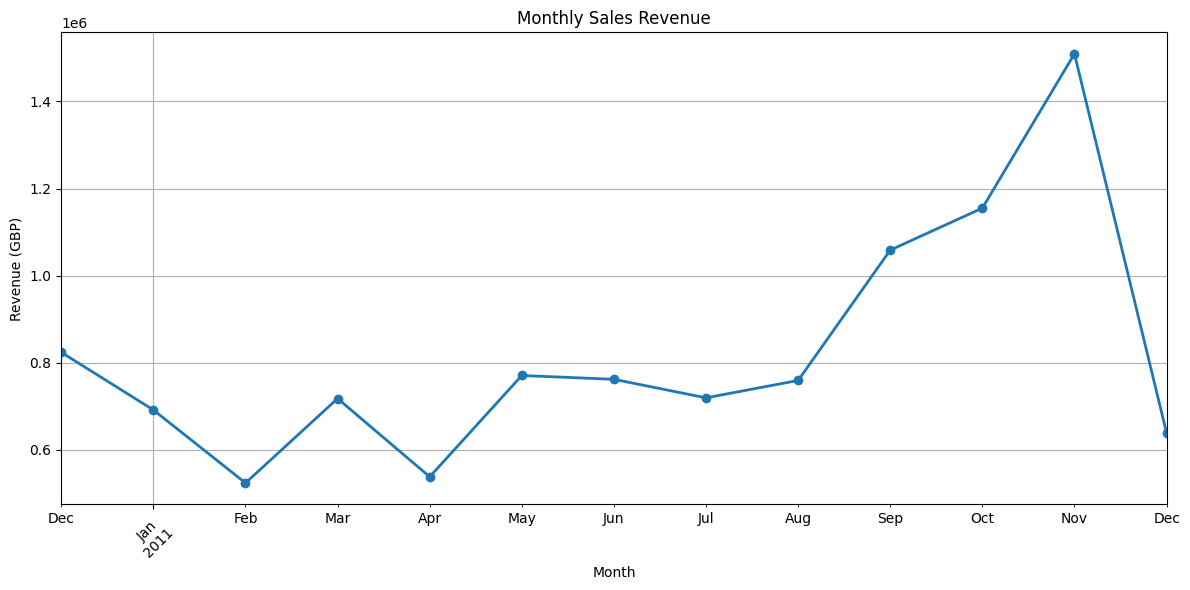

In [15]:
plt.figure(figsize=(12, 6))

monthly_revenue.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [16]:
country_revenue = (
    sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(country_revenue.head(10).round(2))

Country
United Kingdom    9025222.08
Netherlands        285446.34
EIRE               283453.96
Germany            228867.14
France             209715.11
Australia          138521.31
Spain               61577.11
Switzerland         57089.90
Belgium             41196.34
Sweden              38378.33
Name: Revenue, dtype: float64


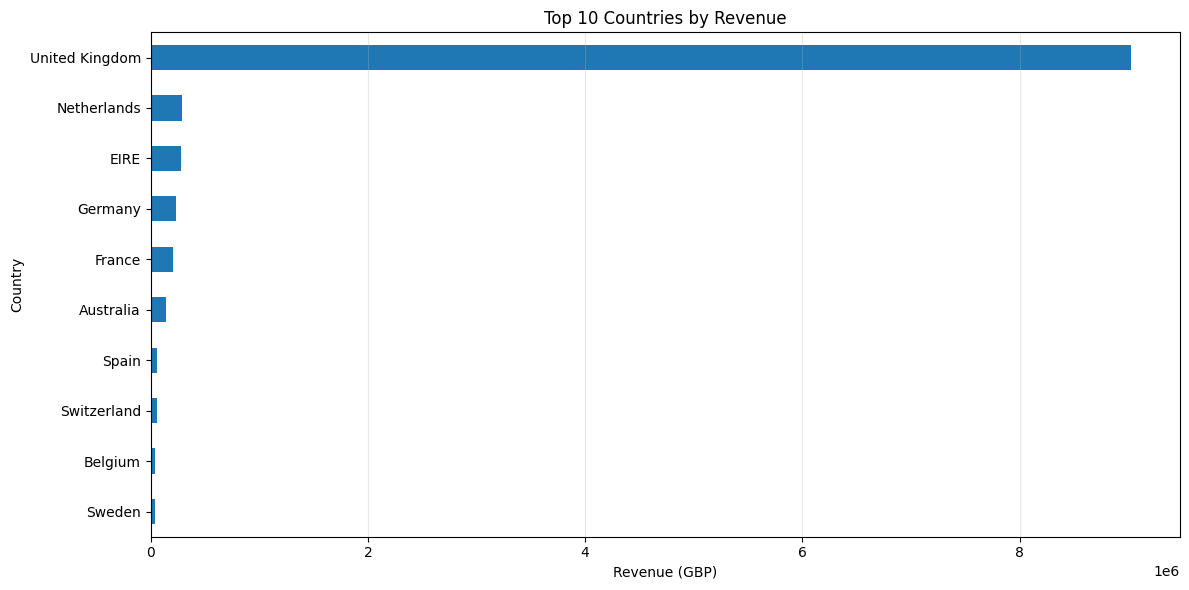

In [17]:
plt.figure(figsize=(12, 6))

country_revenue.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (GBP)")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [18]:
product_revenue = (
    sales.groupby("StockCode")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(product_revenue.head(10).round(2))

StockCode
DOT       206248.77
22423     174484.74
23843     168469.60
85123A    104518.80
47566      99504.33
85099B     94340.05
23166      81700.92
M          78110.27
POST       78101.88
23084      66964.99
Name: Revenue, dtype: float64


In [19]:
product_names = (
    sales.groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
)

top_products = product_revenue.head(10).to_frame()
top_products["Description"] = product_names

print(top_products.round(2))

             Revenue                         Description
StockCode                                               
DOT        206248.77                      DOTCOM POSTAGE
22423      174484.74            REGENCY CAKESTAND 3 TIER
23843      168469.60         PAPER CRAFT , LITTLE BIRDIE
85123A     104518.80  WHITE HANGING HEART T-LIGHT HOLDER
47566       99504.33                       PARTY BUNTING
85099B      94340.05             JUMBO BAG RED RETROSPOT
23166       81700.92      MEDIUM CERAMIC TOP STORAGE JAR
M           78110.27                              Manual
POST        78101.88                             POSTAGE
23084       66964.99                  RABBIT NIGHT LIGHT


<Figure size 1200x700 with 0 Axes>

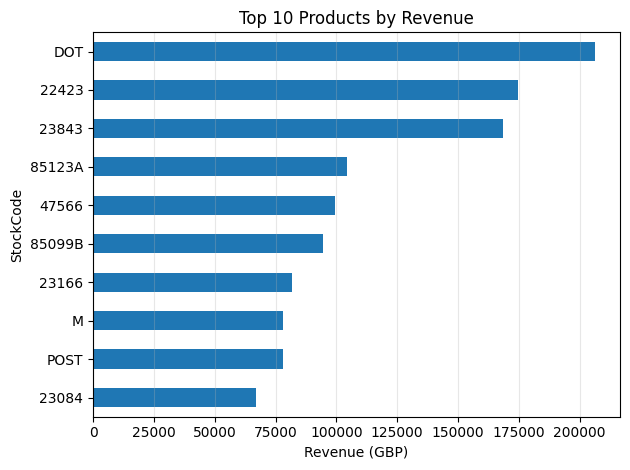

In [20]:
plt.figure(figsize=(12, 7))

top_products.sort_values("Revenue").plot(
    kind="barh",
    y="Revenue",
    legend=False
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (GBP)")
plt.ylabel("StockCode")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [21]:
monthly_orders = (
    sales.groupby(sales["InvoiceDate"].dt.to_period("M"))["InvoiceNo"]
    .nunique()
)

print(monthly_orders)

InvoiceDate
2010-12    1559
2011-01    1086
2011-02    1100
2011-03    1454
2011-04    1246
2011-05    1681
2011-06    1533
2011-07    1475
2011-08    1361
2011-09    1837
2011-10    2040
2011-11    2769
2011-12     819
Freq: M, Name: InvoiceNo, dtype: int64


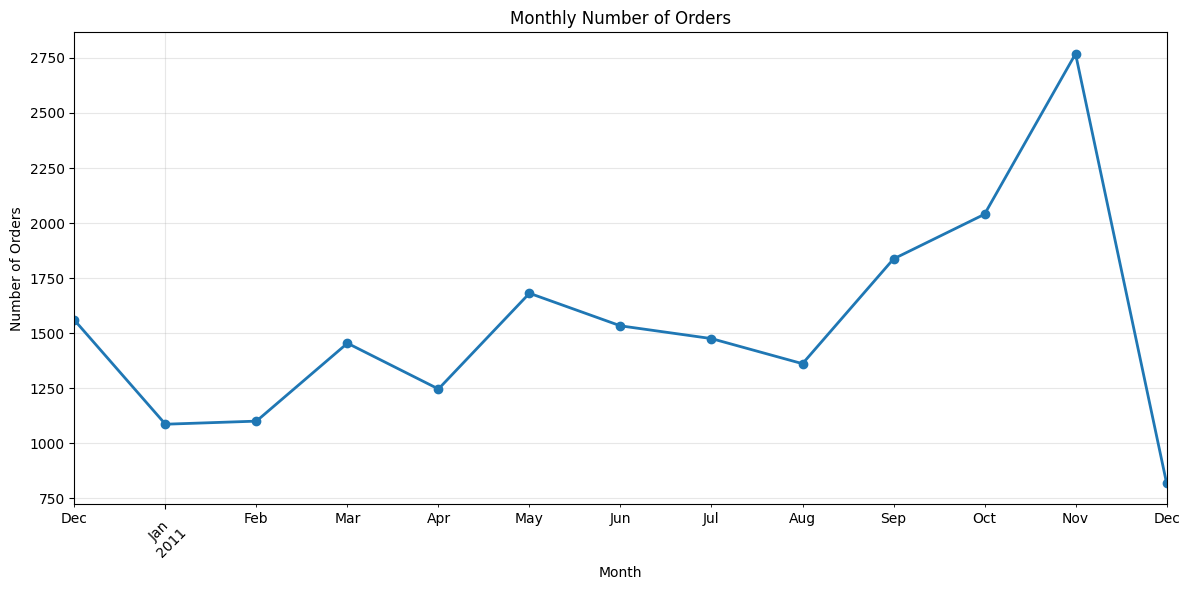

In [22]:
plt.figure(figsize=(12, 6))

monthly_orders.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Monthly Number of Orders")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [23]:
monthly_analysis = pd.DataFrame({
    "Revenue": monthly_revenue,
    "Orders": monthly_orders
})

monthly_analysis["Average_Order_Value"] = (
    monthly_analysis["Revenue"] / monthly_analysis["Orders"]
)

print(monthly_analysis.round(2))

                Revenue  Orders  Average_Order_Value
InvoiceDate                                         
2010-12       823746.14    1559               528.38
2011-01       691364.56    1086               636.62
2011-02       523631.89    1100               476.03
2011-03       717639.36    1454               493.56
2011-04       537808.62    1246               431.63
2011-05       770536.02    1681               458.38
2011-06       761739.90    1533               496.89
2011-07       719221.19    1475               487.61
2011-08       759138.38    1361               557.78
2011-09      1058590.17    1837               576.26
2011-10      1154979.30    2040               566.17
2011-11      1509496.33    2769               545.14
2011-12       638792.68     819               779.97


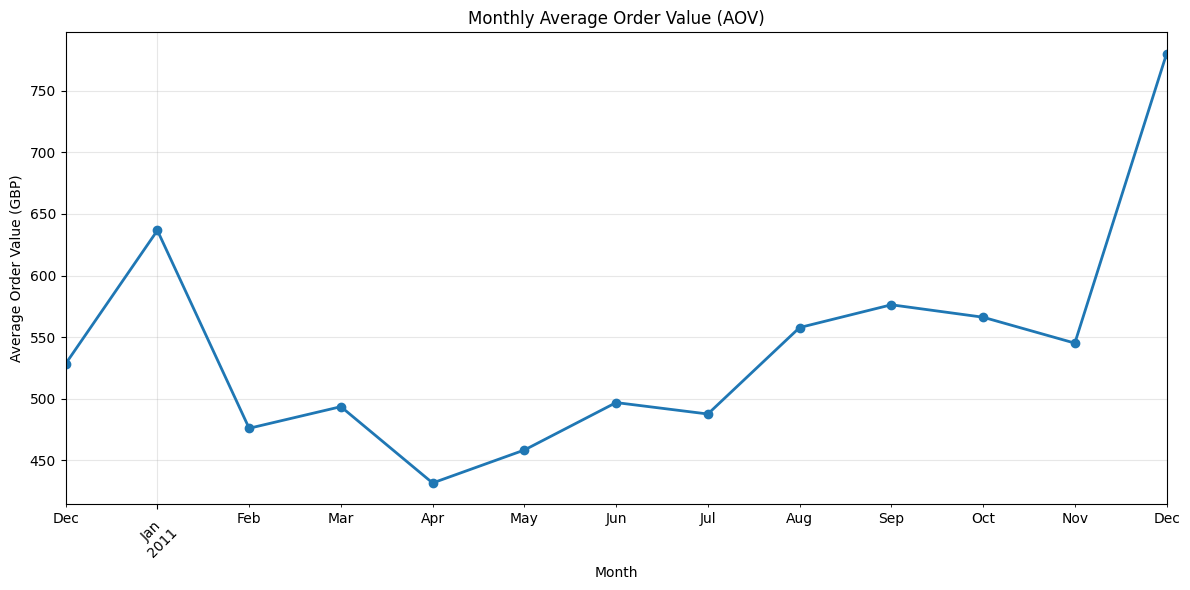

In [24]:
plt.figure(figsize=(12, 6))

monthly_analysis["Average_Order_Value"].plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Order Value (AOV)")
plt.xlabel("Month")
plt.ylabel("Average Order Value (GBP)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [25]:
customer_stats = {
    "Unique customers": sales["CustomerID"].nunique(),
    "Total orders": sales["InvoiceNo"].nunique(),
    "Customers without ID": sales["CustomerID"].isna().sum()
}

print(pd.Series(customer_stats))

Unique customers          4338
Total orders             19960
Customers without ID    132220
dtype: int64


In [26]:
customer_orders = (
    sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

print("Average orders per customer:", round(customer_orders.mean(), 2))
print("Median orders per customer:", customer_orders.median())
print("Maximum orders:", customer_orders.max())

print("\nTop 10 customers by number of orders:")
print(customer_orders.sort_values(ascending=False).head(10))

Average orders per customer: 4.27
Median orders per customer: 2.0
Maximum orders: 209

Top 10 customers by number of orders:
CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


In [27]:
one_time_customers = (customer_orders == 1).sum()
repeat_customers = (customer_orders >= 2).sum()

total_customers = len(customer_orders)

print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)

print("One-time customer share:",
      round(one_time_customers / total_customers * 100, 2), "%")

print("Repeat customer share:",
      round(repeat_customers / total_customers * 100, 2), "%")

One-time customers: 1493
Repeat customers: 2845
One-time customer share: 34.42 %
Repeat customer share: 65.58 %


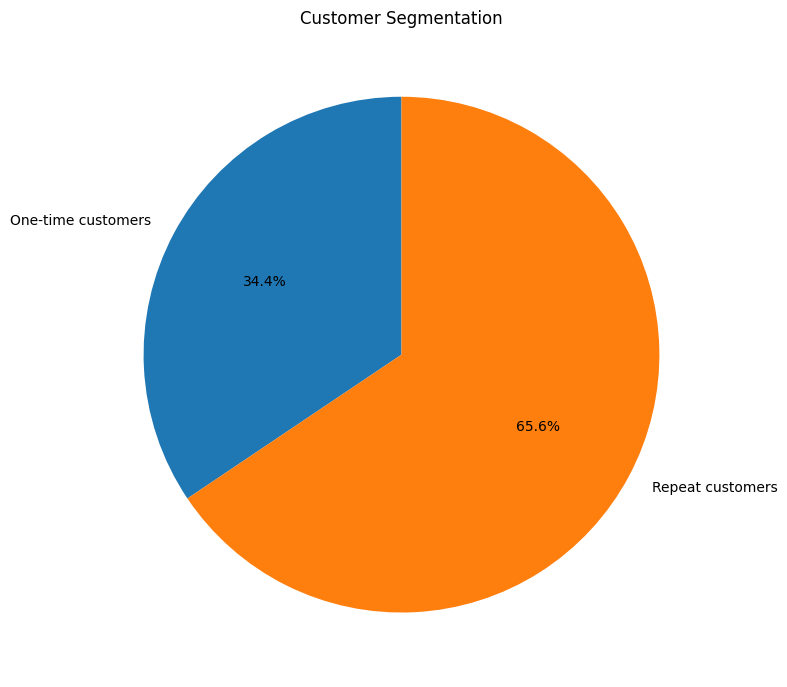

In [28]:
customer_segments = pd.Series({
    "One-time customers": one_time_customers,
    "Repeat customers": repeat_customers
})

plt.figure(figsize=(8, 8))

plt.pie(
    customer_segments,
    labels=customer_segments.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Segmentation")
plt.tight_layout()
plt.show()

In [29]:
customer_revenue = (
    sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 customers by revenue:")
print(customer_revenue.head(10).round(2))

Top 10 customers by revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: Revenue, dtype: float64


In [30]:
customer_analysis = pd.DataFrame({
    "Orders": customer_orders,
    "Revenue": customer_revenue
})

customer_analysis = customer_analysis.sort_values(
    "Revenue",
    ascending=False
)

print(customer_analysis.head(10).round(2))

            Orders    Revenue
CustomerID                   
14646.0         73  280206.02
18102.0         60  259657.30
17450.0         46  194550.79
16446.0          2  168472.50
14911.0        201  143825.06
12415.0         21  124914.53
14156.0         55  117379.63
17511.0         31   91062.38
16029.0         63   81024.84
12346.0          1   77183.60


In [31]:
customer_analysis["Average_Order_Value"] = (
    customer_analysis["Revenue"] /
    customer_analysis["Orders"]
)

print(
    customer_analysis
    .sort_values("Average_Order_Value", ascending=False)
    .head(10)
    .round(2)
)

            Orders    Revenue  Average_Order_Value
CustomerID                                        
16446.0          2  168472.50             84236.25
12346.0          1   77183.60             77183.60
15749.0          3   44534.30             14844.77
15098.0          3   39916.50             13305.50
12357.0          1    6207.67              6207.67
12415.0         21  124914.53              5948.31
12590.0          2    9864.26              4932.13
12688.0          1    4873.81              4873.81
12752.0          1    4366.78              4366.78
18102.0         60  259657.30              4327.62


In [32]:
customer_summary = customer_analysis.copy()

customer_summary = customer_summary.sort_values(
    "Revenue",
    ascending=False
)

print("Total customers:", len(customer_summary))
print("\nCustomer statistics:")
print(customer_summary[[
    "Orders",
    "Revenue",
    "Average_Order_Value"
]].describe().round(2))

Total customers: 4338

Customer statistics:
        Orders    Revenue  Average_Order_Value
count  4338.00    4338.00              4338.00
mean      4.27    2054.27               419.17
std       7.70    8989.23              1796.54
min       1.00       3.75                 3.45
25%       1.00     307.41               178.62
50%       2.00     674.48               293.90
75%       5.00    1661.74               430.11
max     209.00  280206.02             84236.25


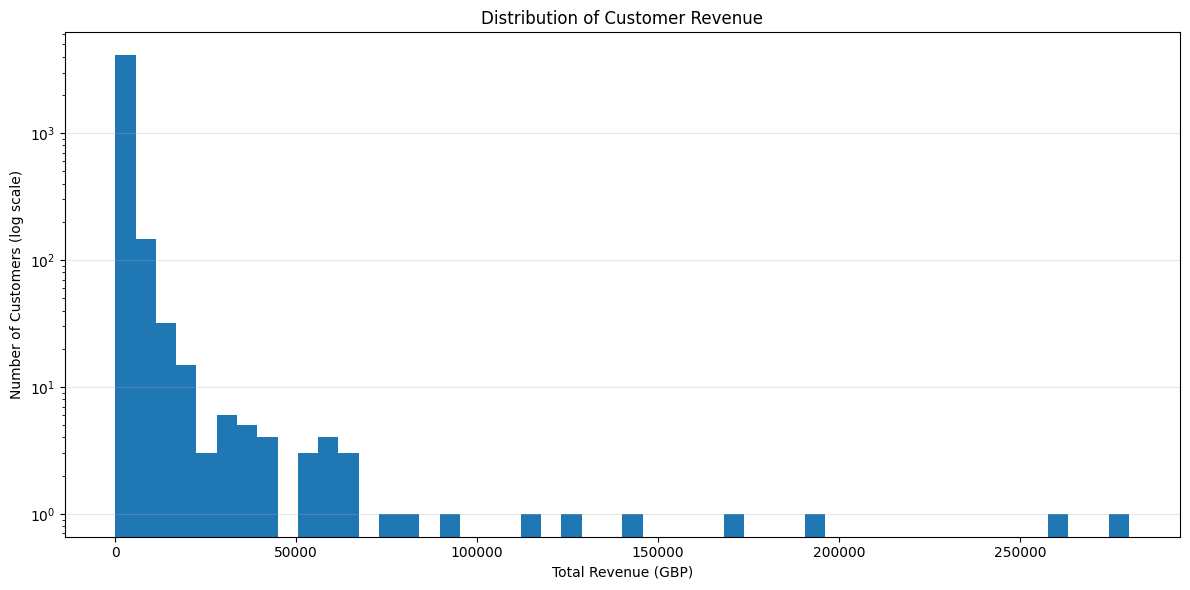

In [33]:
plt.figure(figsize=(12, 6))

plt.hist(
    customer_analysis["Revenue"],
    bins=50,
    log=True
)

plt.title("Distribution of Customer Revenue")
plt.xlabel("Total Revenue (GBP)")
plt.ylabel("Number of Customers (log scale)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
customer_revenue_sorted = customer_analysis["Revenue"].sort_values(
    ascending=False
)

top_10_percent_count = int(np.ceil(len(customer_revenue_sorted) * 0.10))

top_10_percent_revenue = customer_revenue_sorted.head(
    top_10_percent_count
).sum()

total_customer_revenue = customer_revenue_sorted.sum()

top_10_percent_share = (
    top_10_percent_revenue / total_customer_revenue * 100
)

print("Total customers:", len(customer_revenue_sorted))
print("Top 10% customers:", top_10_percent_count)
print("Revenue of top 10%:", round(top_10_percent_revenue, 2))
print("Total customer revenue:", round(total_customer_revenue, 2))
print("Top 10% revenue share:", round(top_10_percent_share, 2), "%")

Total customers: 4338
Top 10% customers: 434
Revenue of top 10%: 5469382.46
Total customer revenue: 8911407.9
Top 10% revenue share: 61.38 %


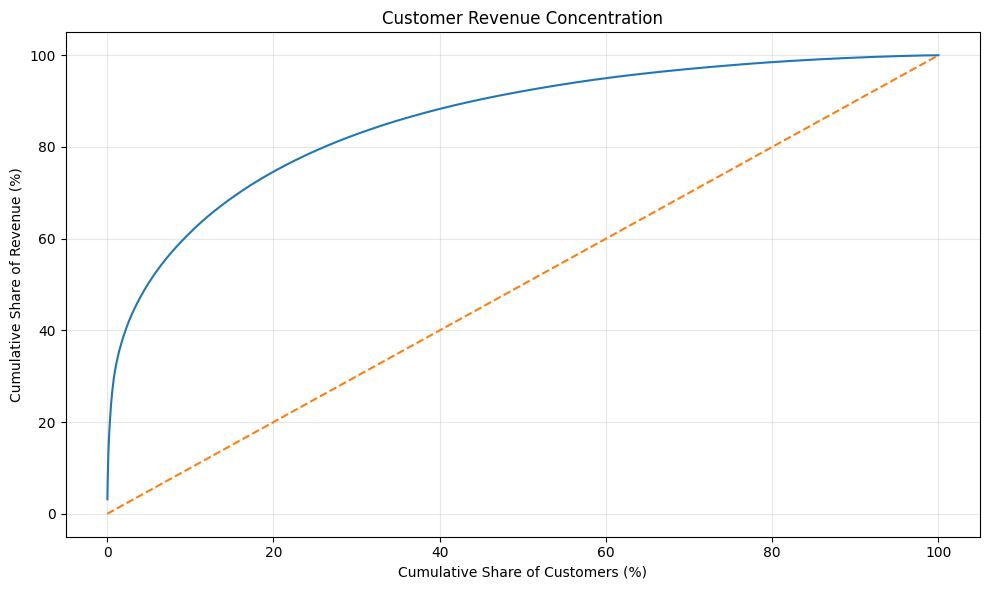

In [35]:
customer_revenue_sorted = customer_analysis["Revenue"].sort_values(
    ascending=False
).reset_index(drop=True)

cumulative_revenue_share = (
    customer_revenue_sorted.cumsum()
    / customer_revenue_sorted.sum()
    * 100
)

customer_share = (
    np.arange(1, len(customer_revenue_sorted) + 1)
    / len(customer_revenue_sorted)
    * 100
)

plt.figure(figsize=(10, 6))

plt.plot(
    customer_share,
    cumulative_revenue_share
)

plt.plot([0, 100], [0, 100], linestyle="--")

plt.title("Customer Revenue Concentration")
plt.xlabel("Cumulative Share of Customers (%)")
plt.ylabel("Cumulative Share of Revenue (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
reference_date = sales["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = (
    sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
)

print(rfm.head(10))
print("\nRFM statistics:")
print(rfm.describe().round(2))

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
12352.0          36          8   2506.04
12353.0         204          1     89.00
12354.0         232          1   1079.40
12355.0         214          1    459.40
12356.0          23          3   2811.43

RFM statistics:
       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2054.27
std     100.01       7.70    8989.23
min       1.00       1.00       3.75
25%      18.00       1.00     307.41
50%      51.00       2.00     674.48
75%     142.00       5.00    1661.74
max     374.00     209.00  280206.02


In [37]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

print(rfm.head(10))

            Recency  Frequency  Monetary R_Score F_Score M_Score RFM_Score
CustomerID                                                                
12346.0         326          1  77183.60       1       1       4       114
12347.0           2          7   4310.00       4       4       4       444
12348.0          75          4   1797.24       2       3       4       234
12349.0          19          1   1757.55       3       1       4       314
12350.0         310          1    334.40       1       1       2       112
12352.0          36          8   2506.04       3       4       4       344
12353.0         204          1     89.00       1       1       1       111
12354.0         232          1   1079.40       1       1       3       113
12355.0         214          1    459.40       1       1       2       112
12356.0          23          3   2811.43       3       3       4       334


In [38]:
rfm_distribution = (
    rfm["RFM_Score"]
    .value_counts()
    .head(15)
)

print("Top 15 RFM segments:")
print(rfm_distribution)

Top 15 RFM segments:
RFM_Score
444    478
111    303
344    222
121    188
112    170
333    163
233    158
211    148
433    129
122    129
222    116
443    108
212    105
244    100
311     98
Name: count, dtype: int64


In [39]:
def segment_customer(row):
    r = int(row["R_Score"])
    f = int(row["F_Score"])
    m = int(row["M_Score"])

    if r >= 3 and f >= 3 and m >= 3:
        return "Champions"

    elif r >= 2 and f >= 3 and m >= 2:
        return "Loyal Customers"

    elif r >= 3 and f <= 2:
        return "Potential Loyalists"

    elif r <= 2 and f >= 2 and m >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2 and m <= 2:
        return "Lost Customers"

    else:
        return "Other"


rfm["Segment"] = rfm.apply(segment_customer, axis=1)

print(
    rfm["Segment"]
    .value_counts()
)

Segment
Champions              1314
Lost Customers         1247
Potential Loyalists     655
Loyal Customers         618
Other                   255
At Risk                 249
Name: count, dtype: int64


In [40]:
segment_analysis = (
    rfm.groupby("Segment")
    .agg(
        Customers=("Monetary", "count"),
        Total_Revenue=("Monetary", "sum"),
        Average_Revenue=("Monetary", "mean"),
        Average_Frequency=("Frequency", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

segment_analysis["Revenue_Share"] = (
    segment_analysis["Total_Revenue"]
    / segment_analysis["Total_Revenue"].sum()
    * 100
)

print(segment_analysis.round(2))

                     Customers  Total_Revenue  Average_Revenue  \
Segment                                                          
Champions                 1314     6494204.98          4942.32   
Loyal Customers            618      865068.64          1399.79   
Potential Loyalists        655      496205.96           757.57   
At Risk                    249      442907.93          1778.75   
Lost Customers            1247      356317.23           285.74   
Other                      255      256703.16          1006.68   

                     Average_Frequency  Revenue_Share  
Segment                                                
Champions                         9.39          72.88  
Loyal Customers                   4.09           9.71  
Potential Loyalists               1.45           5.57  
At Risk                           2.84           4.97  
Lost Customers                    1.19           4.00  
Other                             2.09           2.88  


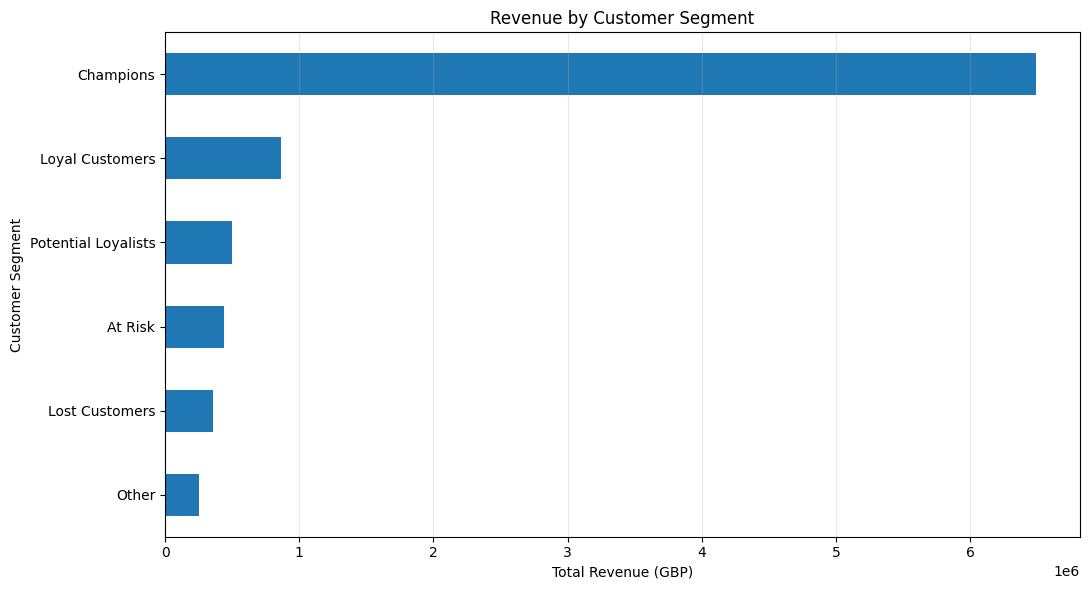

In [41]:
plt.figure(figsize=(11, 6))

segment_analysis["Total_Revenue"].sort_values().plot(
    kind="barh"
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Total Revenue (GBP)")
plt.ylabel("Customer Segment")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
segment_recommendations = {
    "Champions": "Удерживать клиентов, предлагать программы лояльности и персональные предложения.",
    "Loyal Customers": "Стимулировать повторные покупки, предлагать бонусы и дополнительные товары.",
    "Potential Loyalists": "Мотивировать на повторные покупки с помощью скидок и персональных предложений.",
    "At Risk": "Запускать кампании возврата клиентов, анализировать причины снижения активности.",
    "Lost Customers": "Проводить недорогие кампании реактивации и оценивать отклик.",
    "Other": "Дополнительно анализировать поведение и уточнять стратегию взаимодействия."
}

segment_analysis["Recommendation"] = (
    segment_analysis.index.map(segment_recommendations)
)

display(segment_analysis.round(2))

,Customers,Total_Revenue,Average_Revenue,Average_Frequency,Revenue_Share,Recommendation
Segment,,,,,,
Champions,1314,6494204.98,4942.32,9.39,72.88,"Удерживать клиентов, предлагать программы лоял..."
Loyal Customers,618,865068.64,1399.79,4.09,9.71,"Стимулировать повторные покупки, предлагать бо..."
Potential Loyalists,655,496205.96,757.57,1.45,5.57,Мотивировать на повторные покупки с помощью ск...
At Risk,249,442907.93,1778.75,2.84,4.97,"Запускать кампании возврата клиентов, анализир..."
Lost Customers,1247,356317.23,285.74,1.19,4.00,Проводить недорогие кампании реактивации и оце...
Other,255,256703.16,1006.68,2.09,2.88,Дополнительно анализировать поведение и уточня...


In [43]:
rfm.to_csv(
    "../data/processed/rfm_customer_segments.csv",
    index=True
)

segment_analysis.to_csv(
    "../data/processed/segment_analysis.csv",
    index=True
)

print("Files saved successfully")

Files saved successfully


In [44]:
sql_data = sales.copy()

sql_data = sql_data.dropna(subset=["CustomerID"])

sql_data["CustomerID"] = sql_data["CustomerID"].astype(int)

sql_data["Revenue"] = (
    sql_data["Quantity"] * sql_data["UnitPrice"]
)

sql_data.to_csv(
    "../data/processed/sales_for_sql.csv",
    index=False
)

print("Rows:", len(sql_data))
print("Columns:", sql_data.columns.tolist())
print("File saved successfully")

Rows: 397884
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']
File saved successfully
